<font size=15 color="orange"><b> Aproximación de Integral Estocástica por definición 
</b></font>
 
 




·&nbsp; **Diego Marquez Franco** &nbsp;

·&nbsp; **Pablo Rogelio Ramírez Alferes** &nbsp;

·&nbsp; **Carlos Gabriel Barrera Casasola**


# Definiciones

Recordamos que la definición de la integral estocástica de Itô está dada por 

Definición 4.2.2. Sea $f(t, X_t) \in \mathcal{V}[0, T] $. La integral de Itô con respecto al movimiento Browniano $\{W_t\}_{t \ge 0} $ se define como el límite en media cuadrática de las sumas
$$ \sum_{i=0}^{n-1} f(t_i, X_{t_i}) \Delta W_i, $$
cuando la norma de la partición
$$ \|\pi_n\| = \max_{0 \le i \le n-1} (t_{i+1} - t_i) $$
tiende a cero, es decir,
$$ \int_0^T f(t, X_t) \, dW_t = \lim_{\|\pi_n\| \to 0} \sum_{i=0}^{n-1} f(t_i, X_{t_i}) \Delta W_i. $$

Recordemos además que la condición $ f(t, X_t) \in \mathcal{V}[0, T] $ implica que el proceso debe cumplir las siguientes tres propiedades:

1. **Medibilidad conjunta:** la aplicación $(t, \omega) \mapsto f(t, X_t)$ es medible respecto a la $\sigma$-álgebra producto $\mathcal{B}([0,T]) \otimes \mathcal{F}$.

2. **Adaptación al filtrado:** el proceso $f(t, X_t)$ es $\mathcal{F}_t$-medible para cada $t$, es decir, solo depende de la información disponible hasta el instante $t$ (no puede ver el futuro).

3. **Integrabilidad cuadrática:** se satisface la condición 
$$ \mathbb{E}\left[ \int_0^T f(t, X_t)^2 \, dt \right] < \infty, $$
que es precisamente la que garantiza que las sumas de Riemann converjan en media cuadrática, haciendo que la definición anterior sea rigurosa y que la integral resultante sea una martingala.

## Aproximación analítica del Ejemplo 4.4.1

Calcular
$$ I = \int_0^t W_s \, dW_s. $$

Elegimos $X_t = W_t$ y proponemos la función 
$$ f(t, x) = \frac{x^2}{2}. $$

Es decir, debemos elegir una función $f(t, x)$ tal que su derivada parcial con respecto a $x$ sea igual al integrando $W_s$. En este caso, como
$$ f_x = x, $$
al evaluar en $x = W_s$ obtenemos justamente $W_s$, que es lo que queremos integrar.

Aplicando el lema de Itô a $f(t, X_t) = f(t, W_t)$, recordamos que su diferencial es
$$ df(t, W_t) = f_t \, dt + f_x \, dW_t + \frac{1}{2} f_{xx} \, dt. $$

Calculamos las derivadas parciales:
$$ f_t = 0, \qquad f_x = x, \qquad f_{xx} = 1. $$

Sustituyendo en la fórmula de Itô:
$$ d\left( \frac{W_t^2}{2} \right) = 0 \cdot dt + W_t \, dW_t + \frac{1}{2} \cdot 1 \, dt = W_t \, dW_t + \frac{1}{2} dt. $$

Despejando el término que nos interesa:
$$ W_t \, dW_t = d\left( \frac{W_t^2}{2} \right) - \frac{1}{2} dt. $$

Finalmente, integrando ambos lados desde $0$ hasta $t$, obtenemos la solución analítica:
$$ \int_0^t W_s \, dW_s = \frac{W_t^2}{2} - \frac{t}{2}. $$

**Algoritmo 1: Aproximación numérica de la integral de Itô $\displaystyle \int_0^T f(t, W_t)\, dW_t$**

Datos de entrada: $f(t, x)$, $T > 0$, $n \in \mathbb{N}$, semilla (opcional).

1: Dividimos el intervalo $[0,T]$ en $n$ subintervalos de la misma longitud $\Delta = T/n$ con $0 = t_0 < t_1 < \cdots < t_n = T$.

2: Generamos $n$ incrementos brownianos independientes $\Delta W_i \sim \mathcal{N}(0, \Delta)$ para $i = 0, \dots, n-1$ y construimos la trayectoria browniana en los nodos: $W_{t_0} = 0$, $W_{t_i} = \sum_{k=0}^{i-1} \Delta W_k$ para $i = 1,\dots,n$.

3: Inicializamos la suma $S \leftarrow 0$ y el contador $i \leftarrow 0$.

4: Calculamos $S \leftarrow S + f(t_i, W_{t_i}) \Delta W_i$.

5: Si $i = n-1$ terminamos; en otro caso hacemos $i \leftarrow i+1$ y regresamos al paso 4.

6: Devuelve $S$ como aproximación de $\displaystyle \int_0^T f(t, W_t)\, dW_t$.

In [67]:
import numpy as np
import matplotlib.pyplot as plt

def f(t, x):
    return x

def ito_integral_simple(f, T, n ):
    
    dt = T / n
    W = [0] * (n + 1)            # Trayectoria browniana
    integral = [0] * (n + 1)     # Integral acumulada en cada paso
    S = 0
    
    for i in range(n):
        dW_i = np.random.normal(0, np.sqrt(dt))
        W[i+1] = W[i] + dW_i
        t_i = i * dt
        S = S + f(t_i, W[i]) * dW_i
        integral[i+1] = S                        
    return S, W, integral   

T, n = 1, 10000
S_num, W_path, S_acum = ito_integral_simple(f, T, n)

# Solución analítica
W_T = W_path[-1]
S_ana = (W_T**2)/2 - T/2

print(f"Numérica: {S_num:.6f}")
print(f"Analítica: {S_ana:.6f}")
print(f"Error: {abs(S_num - S_ana):.6f}")

Numérica: 0.462712
Analítica: 0.464708
Error: 0.001996


## Grafica de trayectoria y la integral acumulada


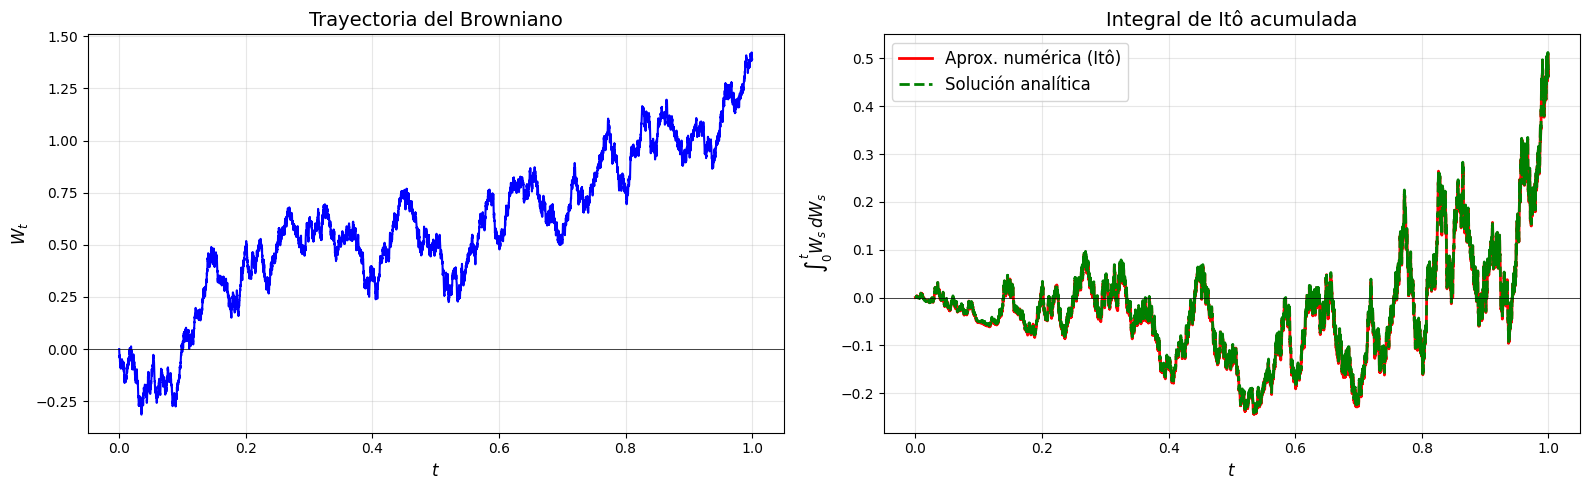

In [68]:
t = np.linspace(0, T, n+1)
W = W_path
S_analitica_trayectoria = [(W[i]**2)/2 - t[i]/2 for i in range(n+1)]

plt.figure(figsize=(16, 5))
# Movimiento Browniano
plt.subplot(1, 2, 1)
plt.plot(t, W, color='blue', linewidth=1.5)
plt.xlabel('$t$', fontsize=12)
plt.ylabel('$W_t$', fontsize=12)
plt.title('Trayectoria del Browniano', fontsize=14)
plt.grid(True, alpha=0.3)
plt.axhline(0, color='black', linewidth=0.5)

# Integral acumulada vs Solución analítica 
plt.subplot(1, 2, 2)
plt.plot(t, S_acum, label='Aprox. numérica (Itô)', color='red', linewidth=2)
plt.plot(t, S_analitica_trayectoria, label='Solución analítica', 
         color='green', linestyle='--', linewidth=2)
plt.xlabel('$t$', fontsize=12)
plt.ylabel('$\int_0^t W_s \, dW_s$', fontsize=12)
plt.title('Integral de Itô acumulada', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=12)
plt.axhline(0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()